In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydhn
from pydhn.fluids import Fluid
from pydhn.soils import Soil
from pydhn.solving import SimpleStep, Scheduler

In [5]:
# ---------------------------------------------------------------------------
# Simulation parameters
# ---------------------------------------------------------------------------
STEPSIZE       = 600          # time step [s]  (10 min)
NUM_SIM_STEPS  = 1008         # 7 days × 144 steps/day
T_AMBIENT_C    = 10.0         # ambient / ground temperature [°C]

In [6]:
# ---------------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------------
PIPES_FILE = "pipes.csv"
NODES_FILE = "nodes.csv"
DEMAND_PROFILE_FILE = "../../data/demand_profile.csv"

# ---------------------------------------------------------------------------
# Load input data
# ---------------------------------------------------------------------------
pipe_data = pd.read_csv(PIPES_FILE)
node_data = pd.read_csv(NODES_FILE)
demand_profile_data = pd.read_csv(DEMAND_PROFILE_FILE)
demand_profile_data = demand_profile_data[:NUM_SIM_STEPS]

time_sim   = demand_profile_data["timestep"].values * STEPSIZE  # [s]
heat_demand = demand_profile_data["Q_W"] * (STEPSIZE / 3600)    # [Wh]
MDOT_BYPASS_KGS = 1.77 / 3600                                   # [kg/s], bypass mass flow

print(f"Loaded topological data from {PIPES_FILE} "
      f"--- dynamic simulation of {len(demand_profile_data)} time steps.")

Loaded topological data from pipes.csv --- dynamic simulation of 1008 time steps.


In [7]:
# ---------------------------------------------------------------------------
# Fluid and soil
# ---------------------------------------------------------------------------
# Properties taken from first pipe row (homogeneous network assumption)
p0 = pipe_data.iloc[0]

fluid = Fluid(
    name       = "Water",
    isconstant = True,
    cp         = p0["fluid_cp_JkgK"],
    mu         = p0["fluid_mu_Pas"],
    rho        = p0["fluid_rho_kgm3"],
    k          = p0["fluid_lambda_WmK"],
)

soil = Soil(
    k    = p0["soil_lambda_WmK"],
    temp = p0["T_ground_degC"],
)

# ---------------------------------------------------------------------------
# Built network
# ---------------------------------------------------------------------------
net = pydhn.Network()

# Add nodes
for _, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]
    X, Y      = row["x_m"], row["y_m"]

    name_s = f"{name}_s"
    name_r = f"{name}_r"

    net.add_node(name=name_s, x=X, y=-Y)
    net.add_node(name=name_r, x=X, y=-Y)

    # Add substations
    if node_type == "substation":
        delta_t = float(row["delta_T_nom_K"])
        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "mass_flow",
            setpoint_type_hyd = "mass_flow",
            setpoint_value_hyd = MDOT_BYPASS_KGS,   # kg/s, initial value
            setpoint_type_hx  = "delta_q",
            setpoint_value_hx = 0.0,                # Wh, initial value
            design_delta_t    = delta_t,
            t_out_min_hx      = 20,
            stepsize          = STEPSIZE,
        )

    # Add central generator
    elif node_type == "source":
        t_supply = float(row["T_supply_set_degC"])
        net.add_producer(
            name                = name,
            start_node          = name_r,
            end_node            = name_s,
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_supply,
            stepsize            = STEPSIZE,
        )

# Add pipes
for _, row in pipe_data.iterrows():
    name = row["pipe_id"]
    frm  = row["from_node"]
    to   = row["to_node"]

    common = dict(
        # --- geometry ---
        diameter                = row["d_inner_m"],                 # carrier pipe inner diameter [m]
        length                  = row["length_m"],                  # pipe length [m]
        internal_pipe_thickness = row["wall_m"],                    # steel wall thickness [m]
        insulation_thickness    = row["insulation_thickness_m"],    # PUR foam thickness [m]
        casing_thickness        = row["casing_thickness_m"],        # HDPE casing wall thickness [m]
        # --- hydraulic ---
        roughness               = row["roughness_mm"],              # absolute roughness [mm]
        # --- thermal: insulation ---
        k_insulation            = row["PUR_lambda_WmK"],            # PUR thermal conductivity [W/(m·K)]
        # --- thermal: carrier pipe ---
        k_internal_pipe         = row["steel_lambda_WmK"],          # steel thermal conductivity [W/(m·K)]
        rho_wall                = row["steel_rho_kgm3"],            # steel density [kg/m³]
        cp_wall                 = row["steel_cp_JkgK"],             # steel specific heat [J/(kg·K)]
        # --- thermal: casing ---
        k_casing                = row["HDPE_lambda_WmK"],           # HDPE thermal conductivity [W/(m·K)]
        # --- burial ---
        depth                   = row["burial_depth_m"],            # burial depth [m]
        h_ext                   = row["h_ext_Wm2K"],                # external heat transfer coeff. [W/(m²·K)]
        # --- simulation ---
        stepsize                = STEPSIZE,                         # time step [s]
    )

    # Supply pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_s",
        start_node = f"{frm}_s",
        end_node   = f"{to}_s",
        line       = "supply",
        **common,
    )

    # Return pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_r",
        start_node = f"{to}_r",
        end_node   = f"{frm}_r",
        line       = "return",
        **common,
    )

print("--- Network setup complete. ---")

--- Network setup complete. ---


In [8]:
# ---------------------------------------------------------------------------
# Schedules
# ---------------------------------------------------------------------------
consumer_demand_schedule   = pd.DataFrame()
consumer_massflow_schedule = pd.DataFrame()
consumer_names = []

for i in node_data.index:
    row       = node_data.loc[i]
    name      = row["node_id"]
    node_type = row["node_type"]

    if node_type == "substation":
        consumer_names.append(name)
        delta_t = float(row["delta_T_nom_K"])

        q_w  = demand_profile_data["Q_W"].values          # [W]
        q_wh = heat_demand

        mdot = np.where(
            q_w == 0,
            MDOT_BYPASS_KGS,                              # bypass [kg/s]
            q_w / (fluid.cp * delta_t)                    # nominal mass flow [kg/s]
        )

        q_schedule = np.where(q_w == 0, 0.0, -q_wh)      # [Wh]

        consumer_massflow_schedule[name] = mdot
        consumer_demand_schedule[name]   = q_schedule

consumer_massflow_schedule = consumer_massflow_schedule[consumer_names]
consumer_demand_schedule   = consumer_demand_schedule[consumer_names]

schedules = {
    "setpoint_value_hyd": consumer_massflow_schedule,   # [kg/s]
    "setpoint_value_hx":  consumer_demand_schedule,     # [Wh]
}

print(f"Schedules built: {len(consumer_names)} consumers × {NUM_SIM_STEPS} steps.")

Schedules built: 10 consumers × 1008 steps.


In [9]:
# ---------------------------------------------------------------------------
# Pre-heating (network initialization)
# ---------------------------------------------------------------------------
print("--- Initializing Network (Pre-heating for stability) ---")

INIT_STEPS = 144  # 1 day

init_demand_consumer = pd.DataFrame(
    np.tile(consumer_demand_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=consumer_demand_schedule.columns,
)

init_schedules = {
    "heat_demand": init_demand_consumer
}

base_loop_init = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler_init = Scheduler(
    base_loop=base_loop_init,
    schedules=init_schedules,
    steps=INIT_STEPS,
)

import time
t0 = time.perf_counter()
_  = scheduler_init.execute(net=net, fluid=fluid, soil=soil)
print(f"Pre-heating done in {time.perf_counter()-t0:.2f} s. "
      f"({INIT_STEPS} steps = {INIT_STEPS*STEPSIZE/3600:.1f} h.)")

--- Initializing Network (Pre-heating for stability) ---
Scheduler started
Step 0:
Loop started


C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\.venv\Lib\site-packages\pydhn\utilities\matrices.py:187: FutureWarning: incidence_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return nx.incidence_matrix(


Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop started
Loop completed
Step 26:
Loop started
Loop completed
Step 27:
Loop started
Loop compl

In [10]:
# ---------------------------------------------------------------------------
# Full simulation
# ---------------------------------------------------------------------------
print("--- Running with Scheduler (Full Simulation) ---")

base_loop_scheduler = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs  ={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler = Scheduler(
    base_loop=base_loop_scheduler,
    schedules=schedules,
    steps=NUM_SIM_STEPS,
)

t0 = time.perf_counter()
results = scheduler.execute(net=net, fluid=fluid, soil=soil)
sim_time = time.perf_counter() - t0

print(f"Simulation complete.")
print(f"Average simulation time: {sim_time:.2f} s.")

--- Running with Scheduler (Full Simulation) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop star

In [11]:
# ---------------------------------------------------------------------------
# Extracted variables
# ---------------------------------------------------------------------------
res = results.to_dataframes()

substation_names = node_data[node_data["node_type"] == "substation"]["node_id"].tolist()
source_name      = node_data[node_data["node_type"] == "source"]["node_id"].iloc[0]
pipe_names       = pipe_data["pipe_id"].tolist()

# ── ETS ──────────────────────────────────────────────────────────────────────
T_sub_s  = res["nodes"]["temperature"][[f"{n}_s" for n in substation_names]]
T_sub_r  = res["nodes"]["temperature"][[f"{n}_r" for n in substation_names]]
mdot_sub = res["edges"]["mass_flow"][substation_names]
Q_sub_W  = res["edges"]["delta_q"][substation_names] / (STEPSIZE / 3600)  # [W]
dT_sub   = pd.DataFrame(
    T_sub_s.values - T_sub_r.values,
    columns=substation_names,
)  # [K]

# ── PRODUCER ─────────────────────────────────────────────────────────────────
T_src_s  = res["nodes"]["temperature"][f"{source_name}_s"]   # supply setpoint check
T_src_r  = res["nodes"]["temperature"][f"{source_name}_r"]
mdot_src = res["edges"]["mass_flow"][source_name]
Q_src_W  = res["edges"]["delta_q"][source_name] / (STEPSIZE / 3600)  # [W]

# ── PIPE ─────────────────────────────────────────────────────────────────────
dp_pipe_s   = res["edges"]["delta_p"][[f"{n}_s"   for n in pipe_names]]   # [Pa]
dp_pipe_r   = res["edges"]["delta_p"][[f"{n}_r"   for n in pipe_names]]   # [Pa]
mdot_pipe_s = res["edges"]["mass_flow"][[f"{n}_s" for n in pipe_names]]   # [kg/s]
mdot_pipe_r = res["edges"]["mass_flow"][[f"{n}_r" for n in pipe_names]]   # [kg/s]
T_pipe_s    = res["edges"]["temperature"][[f"{n}_s" for n in pipe_names]] # [°C]
T_pipe_r    = res["edges"]["temperature"][[f"{n}_r" for n in pipe_names]] # [°C]
Q_loss_pipe_s = res["edges"]["delta_q"][[f"{n}_s" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]
Q_loss_pipe_r = res["edges"]["delta_q"][[f"{n}_r" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]

# ── JUNCTION NODES ───────────────────────────────────────────────────────────
exclude_nodes = (
    {f"{n}_s" for n in substation_names} |
    {f"{n}_r" for n in substation_names} |
    {f"{source_name}_s", f"{source_name}_r"}
)
junction_cols = [c for c in res["nodes"]["temperature"].columns
                 if c not in exclude_nodes]
T_junction = res["nodes"]["temperature"][junction_cols]

# ── ENERGY BALANCE ───────────────────────────────────────────────────────────
SKIP = 144   # steps to skip (1 day initialization)

Q_prod_MWh  =  Q_src_W.iloc[SKIP:].sum() * (STEPSIZE / 3600) / 1e6
Q_cons_MWh  = -Q_sub_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6
Q_loss_MWh  = -(Q_loss_pipe_s.iloc[SKIP:].sum().sum()
               + Q_loss_pipe_r.iloc[SKIP:].sum().sum()) * (STEPSIZE / 3600) / 1e6
eta_network =  Q_cons_MWh / Q_prod_MWh

print("=" * 50)
print("ENERGY BALANCE")
print("=" * 50)
print(f"  Produced:       {Q_prod_MWh:.3f} MWh")
print(f"  Consumed:       {Q_cons_MWh:.3f} MWh")
print(f"  Pipe losses:    {Q_loss_MWh:.3f} MWh")
print(f"  Network η:      {eta_network*100:.1f} %")
print("=" * 50)

# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
import os

results_dir = os.path.join("..", "..", "results")
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(results_dir, "DHN_THV_3G_R_S_BASE_results.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    # ── ETS ──────────────────────────────────────────────────────────────────
    T_sub_s.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_supply_degC")
    T_sub_r.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_return_degC")
    dT_sub.iloc[SKIP:].to_excel(writer,   sheet_name="sub_dT_K")
    mdot_sub.iloc[SKIP:].to_excel(writer, sheet_name="sub_mdot_kgs")
    Q_sub_W.iloc[SKIP:].to_excel(writer,  sheet_name="sub_Q_W")

    # ── PRODUCER ─────────────────────────────────────────────────────────────
    pd.DataFrame({
        "T_supply_degC": T_src_s.values[SKIP:],
        "T_return_degC": T_src_r.values[SKIP:],
        "mdot_kgs":      mdot_src.values[SKIP:],
        "Q_W":           Q_src_W.values[SKIP:],
    }).to_excel(writer, sheet_name="source")

    # ── PIPE ─────────────────────────────────────────────────────────────────
    dp_pipe_s.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_s_dp_Pa")
    dp_pipe_r.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_r_dp_Pa")
    mdot_pipe_s.iloc[SKIP:].to_excel(writer,     sheet_name="pipe_s_mdot_kgs")
    T_pipe_s.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_s_T_out_degC")
    T_pipe_r.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_r_T_out_degC")
    Q_loss_pipe_s.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_s_Qloss_W")
    Q_loss_pipe_r.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_r_Qloss_W")

    # ── JUNCTION NODES ───────────────────────────────────────────────────────
    T_junction.iloc[SKIP:].to_excel(writer, sheet_name="junction_T_degC")

    # ── ENERGY BALANCE ───────────────────────────────────────────────────────
    pd.DataFrame({
        "Q_produced_MWh": [Q_prod_MWh],
        "Q_consumed_MWh": [Q_cons_MWh],
        "Q_losses_MWh":   [Q_loss_MWh],
        "eta_network":    [eta_network],
    }).to_excel(writer, sheet_name="energy_balance")

print(f"Results saved in: {os.path.abspath(output_path)}")

ENERGY BALANCE
  Produced:       67.967 MWh
  Consumed:       63.386 MWh
  Pipe losses:    4.581 MWh
  Network η:      93.3 %
Results saved in: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\results\DHN_THV_3G_R_S_BASE_results.xlsx


In [12]:
# ---------------------------------------------------------------------------
# Results description
# ---------------------------------------------------------------------------
print("""
SIMULATION RESULTS — DHN_THV_3G_R_S_BASE
=========================================

The following results have been extracted from the pyDHN dynamic simulation
of the DHN_THV_3G_R_S_BASE archetype over a 7-day period (1008 time steps
of 10 minutes each). The first 144 steps (1 day) have been discarded as
network initialization (pre-heating) and are not included in the output.

SUBSTATIONS (ETS)
-----------------
- T_supply and T_return: nodal temperatures [°C] at the supply and return
  side of each substation. These reflect the thermal state of the fluid
  entering and leaving the heat exchanger at each energy transfer station.
- dT: effective temperature difference [K] across each substation,
  directly linked to the heat extraction rate and mass flow.
- mdot: mass flow rate [kg/s] imposed at each substation, computed from
  the heat demand profile and the nominal design delta-T. During zero-demand
  periods, a minimum bypass flow of {:.4f} kg/s ({:.2f} kg/h) is maintained
  to ensure hydraulic stability.
- Q: instantaneous thermal power extracted [W] at each substation,
  derived from the simulated energy exchange per time step.

PRODUCER
--------
- T_supply: outlet temperature [°C] of the producer, maintained at the
  fixed setpoint defined in the network configuration.
- T_return: inlet temperature [°C] at the producer, resulting from the
  mixing of return flows from all substations and pipe heat losses.
- mdot: total mass flow rate [kg/s] circulated by the producer,
  equal to the sum of all substation flows.
- Q: total thermal power output [W] of the producer at each time step.

PIPES
-----
- dp (supply / return): pressure drop [Pa] along each pipe segment on
  the supply and return lines, representing the hydraulic resistance
  of the distribution network.
- mdot (supply): mass flow rate [kg/s] through each supply pipe segment,
  reflecting the distribution of flow across the network branches.
- T_out (supply / return): fluid temperature [°C] at the outlet of each
  pipe segment, capturing the thermal losses along the distribution network.
- Q_loss (supply / return): heat loss rate [W] from each pipe segment
  to the surrounding soil, driven by the temperature difference between
  the fluid and the ground (T_ground = {:.1f} °C).

JUNCTION NODES
--------------
- T_junction: fluid temperature [°C] at intermediate network nodes where
  pipe branches meet. These temperatures characterize the thermal mixing
  and propagation across the network topology.

ENERGY BALANCE (post-initialization period)
--------------------------------------------
- Q_produced:    total thermal energy delivered by the producer [{:.3f} MWh]
- Q_consumed:    total thermal energy extracted by all substations [{:.3f} MWh]
- Q_pipe_losses: total heat dispersed to the soil through pipe walls [{:.3f} MWh]
- Network η:     ratio of consumed to produced energy [{:.1f} %],
                 representing the thermal efficiency of the distribution network.
""".format(
    MDOT_BYPASS_KGS,
    MDOT_BYPASS_KGS * 3600,
    pipe_data.iloc[0]["T_ground_degC"],
    Q_prod_MWh,
    Q_cons_MWh,
    Q_loss_MWh,
    eta_network * 100,
))


SIMULATION RESULTS — DHN_THV_3G_R_S_BASE

The following results have been extracted from the pyDHN dynamic simulation
of the DHN_THV_3G_R_S_BASE archetype over a 7-day period (1008 time steps
of 10 minutes each). The first 144 steps (1 day) have been discarded as
network initialization (pre-heating) and are not included in the output.

SUBSTATIONS (ETS)
-----------------
- T_supply and T_return: nodal temperatures [°C] at the supply and return
  side of each substation. These reflect the thermal state of the fluid
  entering and leaving the heat exchanger at each energy transfer station.
- dT: effective temperature difference [K] across each substation,
  directly linked to the heat extraction rate and mass flow.
- mdot: mass flow rate [kg/s] imposed at each substation, computed from
  the heat demand profile and the nominal design delta-T. During zero-demand
  periods, a minimum bypass flow of 0.0005 kg/s (1.77 kg/h) is maintained
  to ensure hydraulic stability.
- Q: instantaneous t

<Axes: >

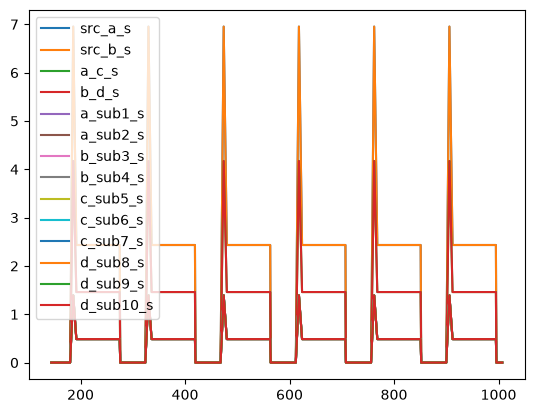

In [17]:
mdot_pipe_s[144:].plot()